# Recolecta+ · Evaluación del agrupamiento K-Means

**APF3 · Sprint 2 · Ruta A (IA implementada)** — continuación de la US-04 (panel general y clústeres).

Este notebook evalúa el mismo modelo que corre en el backend (`backend/ai/clustering.py`, usado por
`cluster_service.py` y por el botón «Optimizar rutas con IA» del panel).

> **Datos simulados.** Los reportes se generan con `simulate_reports.py` alrededor de cinco focos
> inventados en el centro de Chiclayo. No representan puntos críticos reales.

In [1]:
import sys
from pathlib import Path

# En Google Colab se clona el repositorio para usar el mismo código del backend
if "google.colab" in sys.modules and not Path("Recolecta").exists():
    !git clone -q https://github.com/Jamesllm/Recolecta.git

AI_DIR = next(p for p in [Path.cwd().parent, Path.cwd(), Path("Recolecta/backend/ai")] if (p / "clustering.py").exists()).resolve()
sys.path.insert(0, str(AI_DIR))
FIG_DIR = AI_DIR / "notebooks" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import train_test_split

from clustering import TONS_BY_SIZE, choose_k, evaluate_k, fit_kmeans, scores, to_meters, weights_from_sizes
from simulate_reports import CENTER, FOCOS, generate

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Código del modelo:", AI_DIR / "clustering.py")

Código del modelo: C:\Users\Ronal Llapapasca\Documents\Universidad\2026-2\Innovacion\Recolecta+\backend\ai\clustering.py


## 1. Definición del problema de IA

| Campo | Valor |
|---|---|
| Tarea de IA | Clustering (agrupamiento espacial) |
| Pregunta que resuelve | ¿En qué zonas se concentran los reportes pendientes y dónde ubicar el centro de cada ruta de recojo? |
| Salida del modelo | Zona (clúster) de cada reporte y centroide de cada zona |
| Variables de entrada | `x` y `y` en metros (desde latitud y longitud) y el peso de cada reporte = toneladas estimadas según su tamaño |
| Tipo de aprendizaje | No supervisado: no existen etiquetas de «zona correcta» para los reportes |

## 2. Dataset y preparación de datos

In [2]:
df = pd.read_csv(AI_DIR / "data" / "reportes_simulados_chiclayo.csv", parse_dates=["created_at"])
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (400, 7)


,id,lat,lng,category,estimated_size,created_at,foco_real
0,1,-6.774256,-79.841392,Orgánico,small,2026-10-20 05:37:11+00:00,C
1,2,-6.774276,-79.834368,Peligroso,small,2026-11-10 19:44:11+00:00,D
2,3,-6.769602,-79.835569,Inorgánico,small,2026-11-06 03:56:11+00:00,A
3,4,-6.776620,-79.841217,Orgánico,large,2026-10-26 13:26:11+00:00,C
4,5,-6.770493,-79.834943,Escombros,small,2026-10-19 07:12:11+00:00,A


In [3]:
print("Valores nulos por columna:")
print(df.isna().sum().to_string())
print()
print("Reportes duplicados (misma ubicación exacta):", df.duplicated(["lat", "lng"]).sum())
df = df.drop_duplicates(["lat", "lng"]).reset_index(drop=True)
print()
print(df["foco_real"].value_counts().sort_index().rename("reportes").to_frame().T.to_string())
print()
print(pd.crosstab(df["category"], df["estimated_size"], margins=True, margins_name="Total").to_string())

Valores nulos por columna:
id                0
lat               0
lng               0
category          0
estimated_size    0
created_at        0
foco_real         0

Reportes duplicados (misma ubicación exacta): 0

foco_real   A   B   C   D   E  suelto
reportes   98  76  68  53  45      60

estimated_size  large  medium  small  Total
category                                   
Escombros           6      23     31     60
Inorgánico         19      38     81    138
Orgánico           20      54    104    178
Peligroso           2       9     13     24
Total              47     124    229    400


**Preparación:**

1. **Coordenadas a metros.** Un grado de longitud no mide lo mismo que uno de latitud, y K-Means usa
   distancias, así que se proyecta a metros desde la Plaza de Armas (`to_meters`).
2. **Tamaño a peso.** El tamaño es una variable categórica. Se codifica como su carga estimada en toneladas
   (`TONS_BY_SIZE`), con los mismos valores que usa el panel para estimar las toneladas.
3. **Escalado.** No hace falta: `x` y `y` ya están en la misma unidad (metros).

Peso por tamaño (t): {'small': 0.01, 'medium': 0.1, 'large': 2.0}
Rango x: -1096 a 1088 m · rango y: -1097 a 1082 m


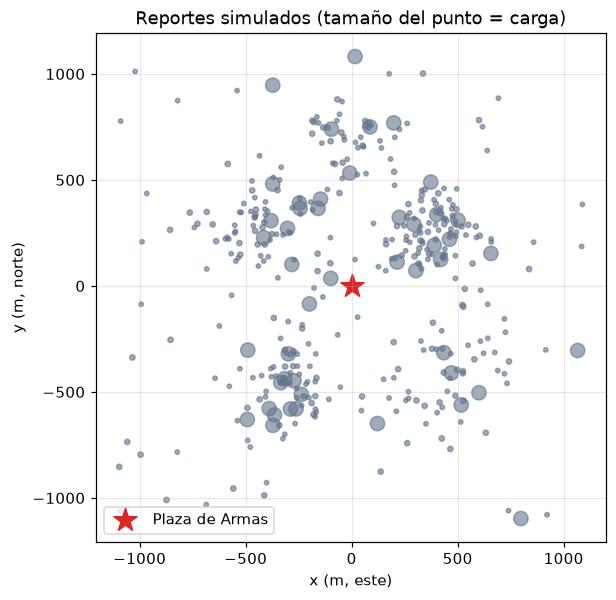

In [4]:
X, REF = to_meters(df["lat"], df["lng"], *CENTER)
w = weights_from_sizes(df["estimated_size"])
print("Peso por tamaño (t):", TONS_BY_SIZE)
print(f"Rango x: {X[:,0].min():.0f} a {X[:,0].max():.0f} m · rango y: {X[:,1].min():.0f} a {X[:,1].max():.0f} m")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X[:, 0], X[:, 1], s=8 + 40 * w, c="#64748b", alpha=0.6)
ax.scatter([0], [0], marker="*", s=250, c="#dc2626", label="Plaza de Armas")
ax.set(title="Reportes simulados (tamaño del punto = carga)", xlabel="x (m, este)", ylabel="y (m, norte)", aspect="equal")
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "01_reportes_simulados.png", bbox_inches="tight")
plt.show()

## 3. Elección de K

Se entrena un modelo por cada K entre 2 y 10 y se comparan tres medidas:

- **Inercia** (método del codo): suma de distancias al cuadrado a cada centroide; siempre baja al subir K.
- **Coeficiente de silueta** (−1 a 1, más alto es mejor): qué tan separados están los grupos.
- **Davies-Bouldin** (más bajo es mejor): parecido entre cada grupo y el más cercano.

El servicio del backend elige automáticamente el K con mayor silueta (`choose_k`).

In [5]:
K_BEST, rows = choose_k(X, w, k_min=2, k_max=10)
tabla_k = pd.DataFrame(rows).set_index("k")
print("K elegido por silueta:", K_BEST)
tabla_k.round(3)

K elegido por silueta: 5


,inertia,silhouette,davies_bouldin
k,,,
2,2.320620e+07,0.412,1.063
3,1.440981e+07,0.423,0.829
4,8.688201e+06,0.486,0.681
5,5.850440e+06,0.512,0.649
6,4.941271e+06,0.497,0.826
7,4.226470e+06,0.498,0.681
8,3.759465e+06,0.436,0.764
9,3.353784e+06,0.358,0.885
10,3.064674e+06,0.335,0.941


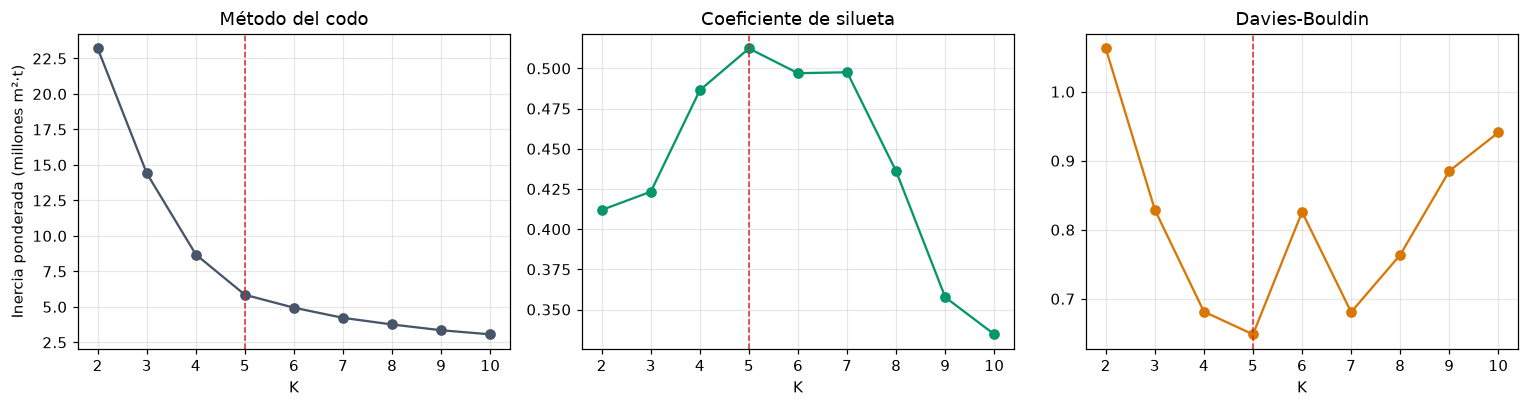

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(tabla_k.index, tabla_k["inertia"] / 1e6, "o-", c="#475569")
axes[0].set(title="Método del codo", xlabel="K", ylabel="Inercia ponderada (millones m²·t)")
axes[1].plot(tabla_k.index, tabla_k["silhouette"], "o-", c="#059669")
axes[1].set(title="Coeficiente de silueta", xlabel="K")
axes[2].plot(tabla_k.index, tabla_k["davies_bouldin"], "o-", c="#d97706")
axes[2].set(title="Davies-Bouldin", xlabel="K")
for ax in axes:
    ax.axvline(K_BEST, ls="--", c="#dc2626", lw=1)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_eleccion_de_k.png", bbox_inches="tight")
plt.show()

## 4. Modelo final

In [7]:
model = fit_kmeans(X, K_BEST, w)
df["cluster"] = model.labels_
sil, db = scores(X, model.labels_)
print(f"K = {K_BEST} · silueta = {sil:.3f} · Davies-Bouldin = {db:.3f}")

resumen = (df.assign(toneladas=w).groupby("cluster")
           .agg(reportes=("id", "size"), toneladas=("toneladas", "sum"))
           .sort_values("toneladas", ascending=False))
resumen["toneladas"] = resumen["toneladas"].round(2)
resumen

K = 5 · silueta = 0.512 · Davies-Bouldin = 0.649


,reportes,toneladas
cluster,,
4,89,27.29
0,112,26.25
1,89,24.94
3,59,16.32
2,51,13.89


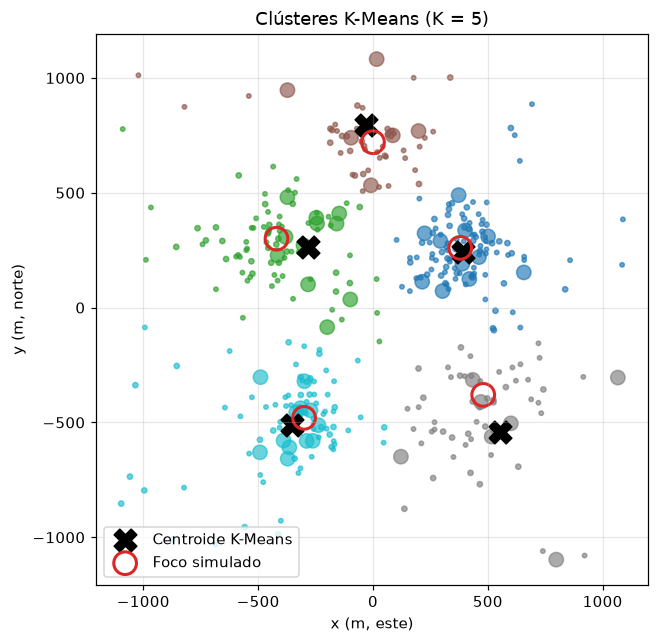

In [8]:
focos_xy = np.array([[c["dx"], c["dy"]] for c in FOCOS.values()])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
sc = ax.scatter(X[:, 0], X[:, 1], s=8 + 40 * w, c=df["cluster"], cmap="tab10", alpha=0.65)
ax.scatter(*model.cluster_centers_.T, marker="X", s=220, c="black", label="Centroide K-Means")
ax.scatter(*focos_xy.T, marker="o", s=220, facecolors="none", edgecolors="#dc2626", lw=2, label="Foco simulado")
ax.set(title=f"Clústeres K-Means (K = {K_BEST})", xlabel="x (m, este)", ylabel="y (m, norte)", aspect="equal")
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "03_clusteres.png", bbox_inches="tight")
plt.show()

## 5. Validación con los focos conocidos

Como los datos son simulados, se sabe de qué foco salió cada reporte. Eso permite medir el modelo
como si tuviera etiquetas (los reportes «sueltos» no pertenecen a ningún foco y se excluyen):

- **Adjusted Rand Index (ARI)**: 1 = los grupos coinciden exactamente con los focos; 0 = como al azar.
- **Tabla de contingencia** foco real × clúster: equivale a una matriz de confusión para clustering.
- **Distancia de cada centroide a su foco**, emparejando centroides y focos con el algoritmo húngaro.

ARI (reportes de algún foco): 0.927


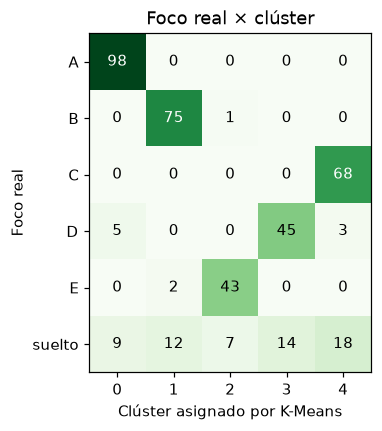

In [9]:
en_foco = df["foco_real"] != "suelto"
ari = adjusted_rand_score(df.loc[en_foco, "foco_real"], df.loc[en_foco, "cluster"])
print(f"ARI (reportes de algún foco): {ari:.3f}")

contingencia = pd.crosstab(df["foco_real"], df["cluster"], rownames=["Foco real"], colnames=["Clúster"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(contingencia.values, cmap="Greens")
ax.grid(False)
ax.set_xticks(range(contingencia.shape[1]), contingencia.columns)
ax.set_yticks(range(contingencia.shape[0]), contingencia.index)
ax.set(xlabel="Clúster asignado por K-Means", ylabel="Foco real", title="Foco real × clúster")
for i in range(contingencia.shape[0]):
    for j in range(contingencia.shape[1]):
        v = contingencia.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color="white" if v > contingencia.values.max() / 2 else "black")
fig.savefig(FIG_DIR / "04_matriz_foco_cluster.png", bbox_inches="tight")
plt.show()

In [10]:
def distancia_a_focos(centroides):
    """Empareja cada foco con un centroide (algoritmo húngaro) y devuelve la distancia en metros."""
    d = np.linalg.norm(focos_xy[:, None, :] - centroides[None, :, :], axis=2)
    filas, cols = linear_sum_assignment(d)
    return pd.Series(d[filas, cols], index=list(FOCOS), name="distancia (m)")

dist = distancia_a_focos(model.cluster_centers_)
print(dist.round(1).to_string())
print(f"Promedio: {dist.mean():.1f} m")

A     21.3
B    142.7
C     61.6
D    176.2
E     78.7
Promedio: 96.1 m


## 6. Entrenamiento y prueba (80 % / 20 %)

K-Means no tiene una respuesta «correcta» que comparar, pero en producción el modelo agrupa reportes
que llegan después de entrenarlo. Para simularlo: se entrena con el 80 % de los reportes y se asigna
el 20 % restante al centroide más cercano (`predict`). En los reportes de prueba se mide:

- el **ARI**, y
- la **asignación correcta**: porcentaje de reportes de prueba que caen en el clúster que
  corresponde a su foco (el clúster donde cayó la mayoría de reportes de ese foco en el entrenamiento).

In [11]:
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["foco_real"])
X_tr, _ = to_meters(train["lat"], train["lng"], *CENTER)
X_te, _ = to_meters(test["lat"], test["lng"], *CENTER)
m_tr = fit_kmeans(X_tr, K_BEST, weights_from_sizes(train["estimated_size"]))

train = train.assign(cluster=m_tr.labels_)
test = test.assign(cluster=m_tr.predict(X_te))
foco_a_cluster = train[train["foco_real"] != "suelto"].groupby("foco_real")["cluster"].agg(lambda s: s.mode()[0])

t = test[test["foco_real"] != "suelto"]
precision = (t["cluster"] == t["foco_real"].map(foco_a_cluster)).mean()
print(f"Entrenamiento: {len(train)} reportes · prueba: {len(test)} reportes ({len(t)} de algún foco)")
print(f"ARI en prueba: {adjusted_rand_score(t['foco_real'], t['cluster']):.3f}")
print(f"Asignación correcta en prueba: {precision:.1%}")

Entrenamiento: 320 reportes · prueba: 80 reportes (68 de algún foco)
ARI en prueba: 0.969
Asignación correcta en prueba: 98.5%


## 7. Comparación con otras opciones

Mismo K y mismos datos, cambiando una decisión cada vez:

1. **Grados en vez de metros** (como estaba el servicio en el Sprint 1). A la latitud de Chiclayo
   (≈ 6,8° S) un grado de longitud mide el 99,3 % de uno de latitud, así que aquí se espera poca diferencia.
2. **Sin pesos** (todos los reportes valen igual). Con pesos, el centroide se mueve hacia donde hay más
   toneladas, así que se aleja del centro geométrico del foco simulado.
3. **DBSCAN** (agrupa por densidad, no pide K y marca como ruido los reportes aislados), con mínimo
   5 reportes por grupo y varios radios. Su silueta se calcula sin los reportes marcados como ruido.

In [12]:
def fila(nombre, labels, centroides=None):
    ok = en_foco.to_numpy()
    con_grupo = labels != -1
    s, _ = scores(X[con_grupo], labels[con_grupo])
    return {
        "opción": nombre,
        "grupos": len(set(labels) - {-1}),
        "ruido": int((~con_grupo).sum()),
        "ARI": adjusted_rand_score(df.loc[ok, "foco_real"], labels[ok]),
        "silueta": s,
        "dist. media a focos (m)": None if centroides is None else distancia_a_focos(centroides).mean(),
    }

grados = fit_kmeans(df[["lng", "lat"]].to_numpy(), K_BEST, w)
grados_xy, _ = to_meters(grados.cluster_centers_[:, 1], grados.cluster_centers_[:, 0], *CENTER)
sin_pesos = fit_kmeans(X, K_BEST)

filas = [
    fila("K-Means en metros con pesos (modelo final)", model.labels_, model.cluster_centers_),
    fila("K-Means en grados con pesos", grados.labels_, grados_xy),
    fila("K-Means en metros sin pesos", sin_pesos.labels_, sin_pesos.cluster_centers_),
]
for eps in [60, 80, 100, 150]:
    filas.append(fila(f"DBSCAN (radio {eps} m, mín. 5)", DBSCAN(eps=eps, min_samples=5).fit(X).labels_))
comparacion = pd.DataFrame(filas).set_index("opción")
comparacion.round(3)

,grupos,ruido,ARI,silueta,dist. media a focos (m)
opción,,,,,
K-Means en metros con pesos (modelo final),5,0,0.927,0.512,96.088
K-Means en grados con pesos,5,0,0.927,0.512,96.088
K-Means en metros sin pesos,5,0,0.922,0.514,47.702
"DBSCAN (radio 60 m, mín. 5)",13,165,0.426,0.431,NaN
"DBSCAN (radio 80 m, mín. 5)",10,112,0.715,0.515,NaN
"DBSCAN (radio 100 m, mín. 5)",6,70,0.738,0.354,NaN
"DBSCAN (radio 150 m, mín. 5)",1,39,0.001,NaN,NaN


## 8. Estabilidad con otros datos simulados

Se repite la elección automática de K y el entrenamiento con 20 datasets generados con semillas
distintas (mismos focos, reportes distintos), con y sin pesos, para ver si los resultados se mantienen.
El valor correcto de K es 5 (cinco focos simulados).

In [13]:
estabilidad = []
for seed in range(1, 21):
    d = generate(400, seed)
    Xs, _ = to_meters(d["lat"], d["lng"], *CENTER)
    ok = (d["foco_real"] != "suelto").to_numpy()
    fila_s = {"semilla": seed}
    for nombre, ws in [("con pesos", weights_from_sizes(d["estimated_size"])), ("sin pesos", None)]:
        k, _ = choose_k(Xs, ws, k_max=10)
        m = fit_kmeans(Xs, k, ws)
        fila_s[f"K {nombre}"] = k
        fila_s[f"ARI {nombre}"] = adjusted_rand_score(d.loc[ok, "foco_real"], m.labels_[ok])
    estabilidad.append(fila_s)
estabilidad = pd.DataFrame(estabilidad).set_index("semilla")

resumen_estabilidad = pd.DataFrame({
    nombre: {
        "datasets con K = 5": int((estabilidad[f"K {nombre}"] == 5).sum()),
        "ARI promedio": estabilidad[f"ARI {nombre}"].mean(),
        "ARI mínimo": estabilidad[f"ARI {nombre}"].min(),
    } for nombre in ["con pesos", "sin pesos"]
})
print(resumen_estabilidad.round(3).to_string())
estabilidad.round(3)

                    con pesos  sin pesos
datasets con K = 5     15.000     12.000
ARI promedio            0.913      0.943
ARI mínimo              0.808      0.899


,K con pesos,ARI con pesos,K sin pesos,ARI sin pesos
semilla,,,,
1,9,0.908,7,0.934
2,5,0.889,5,0.943
3,5,0.895,5,0.949
4,5,0.856,6,0.937
5,6,0.855,6,0.917
6,5,0.924,5,0.943
7,5,0.936,5,0.972
8,6,0.966,6,0.972
9,5,0.888,5,0.899


## 9. Limitaciones conocidas

- Los datos son **simulados**: los resultados muestran que el método funciona cuando existen focos
  claros, no cómo se comportará con reportes reales de Chiclayo.
- K-Means **asigna todos los reportes a algún grupo**, incluidos los sueltos, que pueden alejar un poco
  los centroides.
- K-Means supone grupos más o menos **circulares y de tamaño parecido**; una acumulación alargada
  (por ejemplo, a lo largo de una avenida) podría partirse en dos.
- La silueta se calcula sin pesos: mide la separación geométrica de los grupos, no la carga.
- Con muy pocos reportes pendientes (menos de 3) no se puede calcular la silueta y el servicio
  usa un grupo por reporte.